# Notebook 03: PM2.5 Distribution and Temporal EDA

This notebook examines the behaviour of PM2.5, temperature and station relationships in the final analytical dataset. The purpose is to connect exploratory findings to later modelling decisions, including feature engineering, model selection, masking design and evaluation strategy.

In [1]:
# ============================================================
# Notebook 03: Model-Oriented Exploratory Data Analysis
# Step 1: Setup and load final processed datasets
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 120)

# The model-oriented EDA starts from the processed outputs of Notebook 01.
# This avoids re-parsing raw UK-AIR files and keeps the analysis focused on the final modelling dataset.
DATA_DIR = Path.home() / "Desktop" / "DISSERTATION" / "Codes" / "data" / "processed"

panel_path = DATA_DIR / "selected_pm25_temperature_panel.csv"
metadata_path = DATA_DIR / "selected_station_metadata.csv"
pm25_wide_path = DATA_DIR / "selected_pm25_wide_panel.csv"
temperature_wide_path = DATA_DIR / "selected_temperature_wide_panel.csv"

# Loading both long and wide formats is useful because different EDA tasks need different structures.
# The long panel is easier for grouping by station, month or season.
# The wide panel is easier for station-to-station correlation and spatial analysis.
panel = pd.read_csv(panel_path)
metadata = pd.read_csv(metadata_path)
pm25_wide = pd.read_csv(pm25_wide_path)
temperature_wide = pd.read_csv(temperature_wide_path)

# Datetime conversion is required because temporal EDA depends on extracting year, month, hour and season.
panel["Datetime"] = pd.to_datetime(panel["Datetime"])
pm25_wide["Datetime"] = pd.to_datetime(pm25_wide["Datetime"])
temperature_wide["Datetime"] = pd.to_datetime(temperature_wide["Datetime"])

print("Main panel shape:", panel.shape)
print("Metadata shape:", metadata.shape)
print("PM2.5 wide shape:", pm25_wide.shape)
print("Temperature wide shape:", temperature_wide.shape)

display(panel.head())
display(metadata)

Main panel shape: (219120, 5)
Metadata shape: (5, 7)
PM2.5 wide shape: (43824, 6)
Temperature wide shape: (43824, 6)


,Station,Datetime,RawYear,PM25,Temperature
0,London Bexley,2021-01-01 01:00:00,2021,39.552,-1.2
1,London Bexley,2021-01-01 02:00:00,2021,52.359,-1.9
2,London Bexley,2021-01-01 03:00:00,2021,20.920,-2.3
3,London Bexley,2021-01-01 04:00:00,2021,15.943,-2.8
4,London Bexley,2021-01-01 05:00:00,2021,17.076,-3.2


,Station,Latitude,Longitude,SiteType,Zone,Agglomeration,LocalAuthority
0,London Bexley,51.466030,0.184806,Suburban Background,Greater London,Greater London Urban Area,Bexley
1,London Harlington,51.488790,-0.441614,Urban Industrial,Greater London,Greater London Urban Area,Hillingdon
2,London Honor Oak Park,51.449674,-0.037418,Urban Background,Greater London,Greater London Urban Area,Lewisham
3,London Marylebone Road,51.522530,-0.154611,Urban Traffic,Greater London,Greater London Urban Area,Westminster
4,London N. Kensington,51.521050,-0.213419,Urban Background,Greater London,Greater London Urban Area,Kensington


In [2]:
# ============================================================
# Step 2: Create temporal features for model-oriented EDA
# ============================================================

# A separate EDA copy is used so analysis-specific variables can be added
# without changing the original processed modelling panel.
eda = panel.copy()

# These temporal variables are needed because later models may use time-based features
# such as hour-of-day, day-of-week and seasonal context.
# They also help test whether PM2.5 has temporal patterns that simple models may miss.
eda["Year"] = eda["Datetime"].dt.year
eda["Month"] = eda["Datetime"].dt.month
eda["Hour"] = eda["Datetime"].dt.hour
eda["DayOfWeek"] = eda["Datetime"].dt.day_name()

# Season is added because PM2.5 and meteorological conditions can vary across the year.
# This allows later comparison of pollution levels and model difficulty by seasonal context.
def assign_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

eda["Season"] = eda["Month"].apply(assign_season)

print("EDA dataset shape:", eda.shape)
display(eda.head())

EDA dataset shape: (219120, 10)


,Station,Datetime,RawYear,PM25,Temperature,Year,Month,Hour,DayOfWeek,Season
0,London Bexley,2021-01-01 01:00:00,2021,39.552,-1.2,2021,1,1,Friday,Winter
1,London Bexley,2021-01-01 02:00:00,2021,52.359,-1.9,2021,1,2,Friday,Winter
2,London Bexley,2021-01-01 03:00:00,2021,20.920,-2.3,2021,1,3,Friday,Winter
3,London Bexley,2021-01-01 04:00:00,2021,15.943,-2.8,2021,1,4,Friday,Winter
4,London Bexley,2021-01-01 05:00:00,2021,17.076,-3.2,2021,1,5,Friday,Winter


## Step 3: PM2.5 distribution analysis

This step examines the distribution of observed PM2.5 values. This is important because PM2.5 is the target variable for imputation, and its distribution affects both model behaviour and evaluation.

Air pollution data are often right-skewed, with many low or moderate values and fewer high pollution episodes. High PM2.5 values should not automatically be removed because they may represent real pollution events. Understanding the distribution helps justify the later use of both MAE and RMSE, because RMSE is more sensitive to large errors during high-pollution periods.

In [3]:
# ============================================================
# Step 3: PM2.5 descriptive statistics and percentiles
# ============================================================

# Only observed PM2.5 values are analysed here because the aim is to understand
# the real measured target distribution before any artificial masking is applied.
pm25_observed = eda["PM25"].dropna()

# Descriptive statistics help assess whether PM2.5 has a symmetric distribution
# or a long right tail of high pollution values.
# This matters because skewness and extreme values can affect model errors and metric choice.
pm25_distribution_summary = pd.DataFrame({
    "Metric": [
        "Count",
        "Mean",
        "Median",
        "Standard deviation",
        "Minimum",
        "25th percentile",
        "75th percentile",
        "90th percentile",
        "95th percentile",
        "99th percentile",
        "Maximum",
        "Skewness"
    ],
    "Value": [
        pm25_observed.count(),
        round(pm25_observed.mean(), 2),
        round(pm25_observed.median(), 2),
        round(pm25_observed.std(), 2),
        round(pm25_observed.min(), 2),
        round(pm25_observed.quantile(0.25), 2),
        round(pm25_observed.quantile(0.75), 2),
        round(pm25_observed.quantile(0.90), 2),
        round(pm25_observed.quantile(0.95), 2),
        round(pm25_observed.quantile(0.99), 2),
        round(pm25_observed.max(), 2),
        round(pm25_observed.skew(), 2)
    ]
})

display(pm25_distribution_summary)

,Metric,Value
0,Count,214013.00
1,Mean,8.64
2,Median,6.42
3,Standard deviation,7.43
4,Minimum,0.00
5,25th percentile,4.11
6,75th percentile,10.54
7,90th percentile,17.00
8,95th percentile,23.00
9,99th percentile,37.92


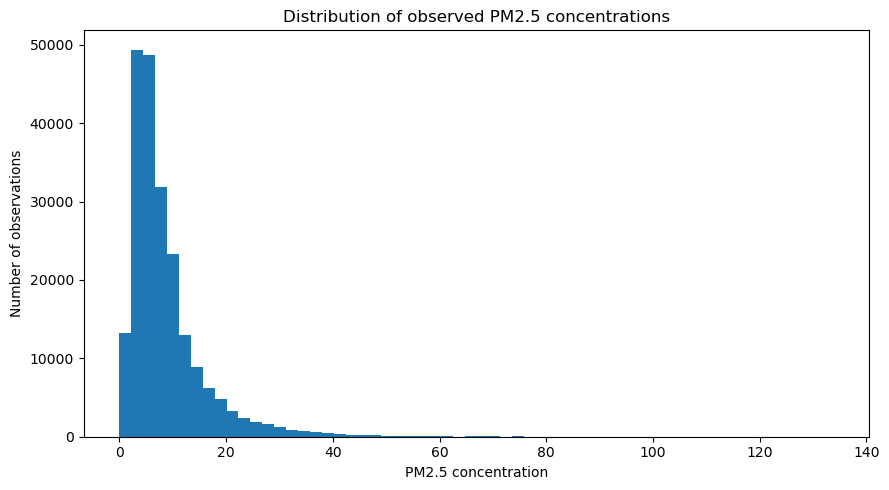

In [4]:
# ============================================================
# Step 3.1: Visualise the full PM2.5 distribution
# ============================================================

# The full histogram shows the complete observed PM2.5 range.
# This helps identify whether the target variable contains a long right tail
# and high pollution episodes that may be difficult for imputation models.
plt.figure(figsize=(9, 5))

plt.hist(
    pm25_observed,
    bins=60
)

plt.xlabel("PM2.5 concentration")
plt.ylabel("Number of observations")
plt.title("Distribution of observed PM2.5 concentrations")

plt.tight_layout()
plt.show()

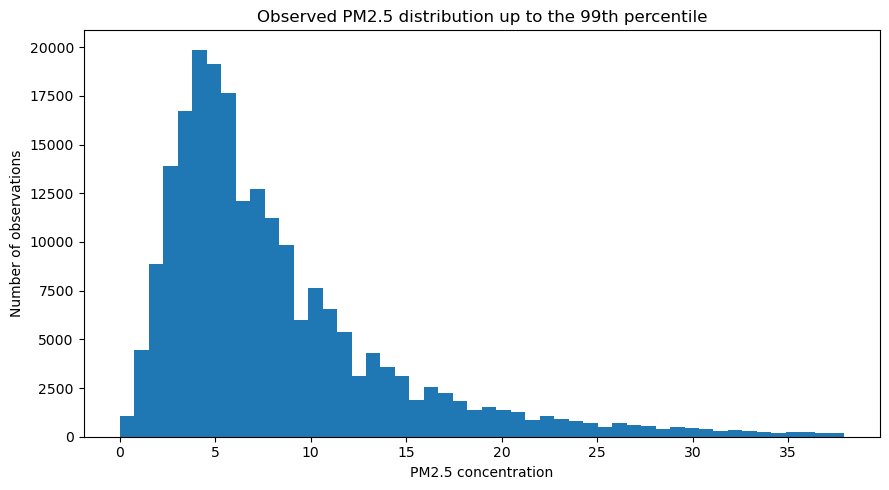

99th percentile PM2.5: 37.92


In [5]:
# ============================================================
# Step 3.2: Visualise the main PM2.5 distribution up to the 99th percentile
# ============================================================

# Very high PM2.5 values can compress the main part of the histogram.
# Limiting the plot to the 99th percentile improves readability without removing
# those high values from the dataset.
pm25_99th = pm25_observed.quantile(0.99)

plt.figure(figsize=(9, 5))

plt.hist(
    pm25_observed[pm25_observed <= pm25_99th],
    bins=50
)

plt.xlabel("PM2.5 concentration")
plt.ylabel("Number of observations")
plt.title("Observed PM2.5 distribution up to the 99th percentile")

plt.tight_layout()
plt.show()

print("99th percentile PM2.5:", round(pm25_99th, 2))

In [6]:
# ============================================================
# Step 3.3: PM2.5 descriptive statistics by station
# ============================================================

# Station-level PM2.5 summaries show whether pollution behaviour differs across monitoring sites.
# This matters because station-specific distributions can affect imputation difficulty,
# especially when comparing traffic, urban background, suburban and industrial sites.
station_pm25_summary = (
    eda.groupby("Station")
    .agg(
        Observed_PM25=("PM25", lambda x: x.notna().sum()),
        Mean_PM25=("PM25", "mean"),
        Median_PM25=("PM25", "median"),
        Std_PM25=("PM25", "std"),
        P95_PM25=("PM25", lambda x: x.quantile(0.95)),
        Max_PM25=("PM25", "max")
    )
    .reset_index()
)

# Rounded values make the station comparison easier to read and report.
numeric_cols = ["Mean_PM25", "Median_PM25", "Std_PM25", "P95_PM25", "Max_PM25"]
station_pm25_summary[numeric_cols] = station_pm25_summary[numeric_cols].round(2)

# Sorting by mean PM2.5 highlights which stations have higher typical concentrations.
station_pm25_summary = station_pm25_summary.sort_values("Mean_PM25", ascending=False)

display(station_pm25_summary)

,Station,Observed_PM25,Mean_PM25,Median_PM25,Std_PM25,P95_PM25,Max_PM25
3,London Marylebone Road,39900,11.02,9.00,7.53,25.00,90.00
0,London Bexley,43607,8.86,6.32,8.00,24.62,133.87
4,London N. Kensington,43594,8.20,5.94,7.33,22.36,98.02
2,London Honor Oak Park,43282,7.74,5.60,6.91,21.32,90.35
1,London Harlington,43630,7.58,5.46,6.84,20.78,121.32


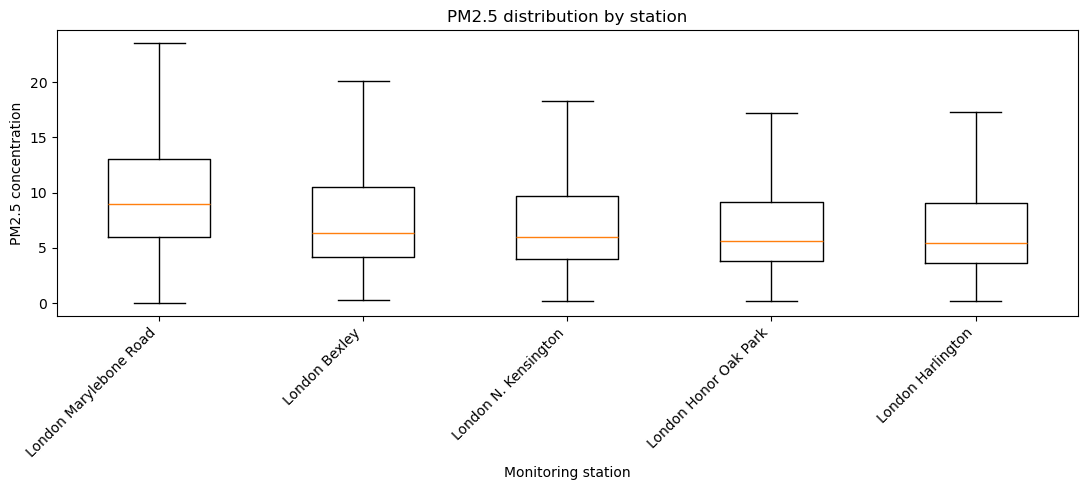

In [7]:
# ============================================================
# Step 3.4: Visualise PM2.5 distribution by station
# ============================================================

# A boxplot compares the central tendency and spread of PM2.5 across stations.
# This helps identify whether different monitoring sites may require models to handle
# different pollution ranges and variability.
stations_order = station_pm25_summary["Station"].tolist()

boxplot_data = [
    eda.loc[eda["Station"] == station, "PM25"].dropna()
    for station in stations_order
]

plt.figure(figsize=(11, 5))

plt.boxplot(
    boxplot_data,
    labels=stations_order,
    showfliers=False
)

plt.ylabel("PM2.5 concentration")
plt.xlabel("Monitoring station")
plt.title("PM2.5 distribution by station")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [8]:
# ============================================================
# Step 3.5: High PM2.5 episodes by station
# ============================================================

# High PM2.5 episodes are examined because pollution spikes may be harder to impute
# than normal low or moderate concentrations.
# These values are retained because they may represent real air quality events.
high_pm25_threshold = pm25_observed.quantile(0.95)

high_pm25_by_station = (
    eda[eda["PM25"] >= high_pm25_threshold]
    .groupby("Station")
    .size()
    .reset_index(name="High_PM25_observations")
)

# This percentage makes the high-value comparison fairer across stations,
# especially because each station may have slightly different numbers of observed PM2.5 readings.
high_pm25_by_station["Percentage_of_station_observed_PM25"] = high_pm25_by_station.apply(
    lambda row: round(
        row["High_PM25_observations"] /
        eda.loc[
            (eda["Station"] == row["Station"]) & (eda["PM25"].notna()),
            "PM25"
        ].shape[0] * 100,
        2
    ),
    axis=1
)

high_pm25_by_station = high_pm25_by_station.sort_values(
    "High_PM25_observations",
    ascending=False
)

print("High PM2.5 threshold based on 95th percentile:", round(high_pm25_threshold, 2))
display(high_pm25_by_station)

High PM2.5 threshold based on 95th percentile: 23.0


,Station,High_PM25_observations,Percentage_of_station_observed_PM25
3,London Marylebone Road,2644,6.63
0,London Bexley,2582,5.92
4,London N. Kensington,2041,4.68
2,London Honor Oak Park,1747,4.04
1,London Harlington,1700,3.90


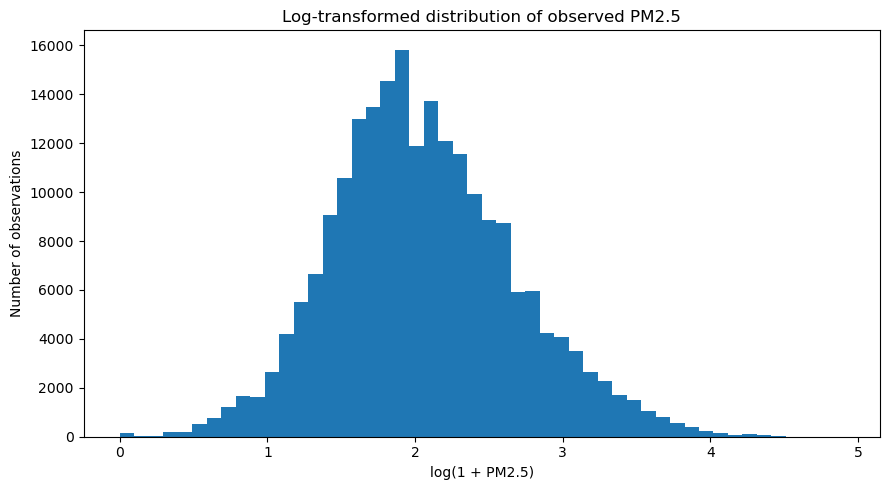

In [9]:
# ============================================================
# Step 3.6: Log-transformed PM2.5 distribution for visual inspection
# ============================================================

# PM2.5 is right-skewed, so a log-transformed view helps show the distribution
# more clearly. This is only for EDA visualisation and does not mean the target
# variable will automatically be transformed for all models.

plt.figure(figsize=(9, 5))

plt.hist(
    np.log1p(pm25_observed),
    bins=50
)

plt.xlabel("log(1 + PM2.5)")
plt.ylabel("Number of observations")
plt.title("Log-transformed distribution of observed PM2.5")

plt.tight_layout()
plt.show()

### Step 3 interpretation

The PM2.5 distribution is clearly right-skewed. The mean concentration is 8.64, while the median is lower at 6.42, showing that the average is pulled upward by higher pollution episodes. The skewness value of 2.91 confirms a long right tail in the distribution.

Most observed PM2.5 values are relatively low or moderate, but the dataset also contains high pollution episodes. The 95th percentile is 23.00, the 99th percentile is 37.92, and the maximum observed value is 133.87. These high values should not automatically be removed because they may represent real pollution events rather than data errors.

This distribution has direct implications for model evaluation. MAE is useful because it measures typical absolute error, while RMSE is also needed because it penalises large errors more strongly. This is important for PM2.5 imputation because failing to reconstruct high-pollution episodes may be more serious than small errors during normal conditions.

Station-level analysis also shows that PM2.5 behaviour differs across monitoring sites. London Marylebone Road has the highest number and percentage of high PM2.5 observations above the 95th percentile, followed by London Bexley. This suggests that imputation difficulty may vary by station and supports later station-level model evaluation.

## Step 4: Temporal PM2.5 patterns

This step examines how observed PM2.5 concentrations vary across months, seasons, hours of the day and days of the week. This is important because PM2.5 is a time-dependent pollutant, and imputation models may perform better when temporal structure is represented through features such as month, season, hour-of-day and lagged PM2.5 values.

This analysis helps justify later temporal feature engineering. If PM2.5 shows monthly, seasonal or hourly variation, then simple global imputation methods may be too limited because they ignore when the missing value occurs.

In [10]:
# ============================================================
# Step 4: Monthly PM2.5 patterns
# ============================================================

# Monthly PM2.5 patterns are examined because air pollution can vary across the year.
# If PM2.5 changes by month, later models may benefit from temporal features
# instead of treating all missing values as identical.

month_pm25_summary = (
    eda.groupby("Month")
    .agg(
        Observed_PM25=("PM25", lambda x: x.notna().sum()),
        Mean_PM25=("PM25", "mean"),
        Median_PM25=("PM25", "median"),
        P95_PM25=("PM25", lambda x: x.quantile(0.95))
    )
    .reset_index()
)

# Rounding makes the table easier to interpret in the notebook and later dissertation write-up.
month_pm25_summary[["Mean_PM25", "Median_PM25", "P95_PM25"]] = (
    month_pm25_summary[["Mean_PM25", "Median_PM25", "P95_PM25"]].round(2)
)

display(month_pm25_summary)

,Month,Observed_PM25,Mean_PM25,Median_PM25,P95_PM25
0,1,17368,10.39,7.90,26.95
1,2,16277,10.15,7.24,29.00
2,3,18321,13.30,8.73,39.24
3,4,17840,9.41,7.20,23.77
4,5,18363,8.14,6.89,18.68
5,6,17830,7.75,6.60,16.91
6,7,17933,6.27,5.00,14.34
7,8,18390,6.42,5.29,14.53
8,9,17285,8.21,5.78,22.64
9,10,18371,7.03,5.85,16.00


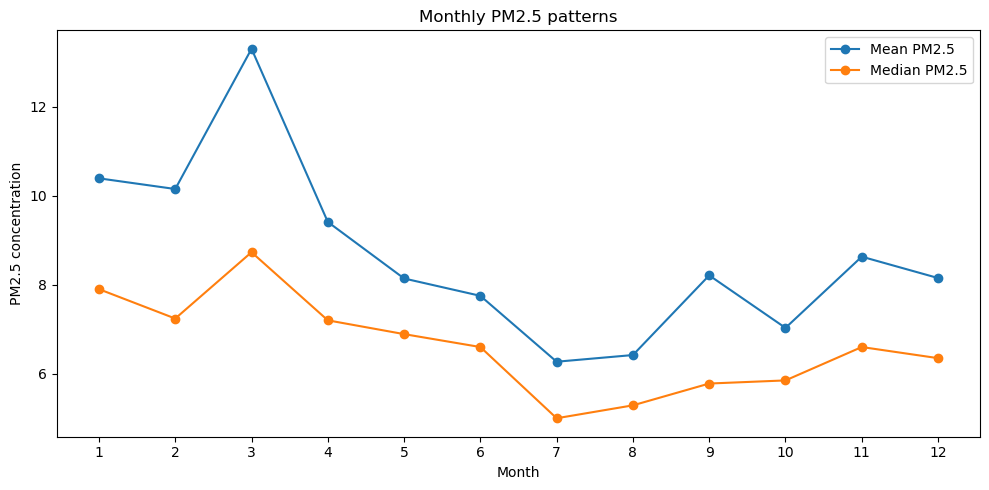

In [11]:
# ============================================================
# Step 4.1: Visualise monthly PM2.5 patterns
# ============================================================

# Mean and median are shown together because PM2.5 is right-skewed.
# If the mean is consistently higher than the median, this suggests that high pollution
# episodes influence monthly averages.

plt.figure(figsize=(10, 5))

plt.plot(
    month_pm25_summary["Month"],
    month_pm25_summary["Mean_PM25"],
    marker="o",
    label="Mean PM2.5"
)

plt.plot(
    month_pm25_summary["Month"],
    month_pm25_summary["Median_PM25"],
    marker="o",
    label="Median PM2.5"
)

plt.xlabel("Month")
plt.ylabel("PM2.5 concentration")
plt.title("Monthly PM2.5 patterns")
plt.xticks(range(1, 13))
plt.legend()

plt.tight_layout()
plt.show()

In [12]:
# ============================================================
# Step 4.2: Seasonal PM2.5 patterns
# ============================================================

# Seasonal PM2.5 patterns are analysed because pollution behaviour may differ
# under different meteorological and emission conditions.
# This can help later interpretation of model performance by season.

season_order = ["Winter", "Spring", "Summer", "Autumn"]

season_pm25_summary = (
    eda.groupby("Season")
    .agg(
        Observed_PM25=("PM25", lambda x: x.notna().sum()),
        Mean_PM25=("PM25", "mean"),
        Median_PM25=("PM25", "median"),
        P95_PM25=("PM25", lambda x: x.quantile(0.95))
    )
    .reset_index()
)

season_pm25_summary["Season"] = pd.Categorical(
    season_pm25_summary["Season"],
    categories=season_order,
    ordered=True
)

season_pm25_summary = season_pm25_summary.sort_values("Season")

season_pm25_summary[["Mean_PM25", "Median_PM25", "P95_PM25"]] = (
    season_pm25_summary[["Mean_PM25", "Median_PM25", "P95_PM25"]].round(2)
)

display(season_pm25_summary)

,Season,Observed_PM25,Mean_PM25,Median_PM25,P95_PM25
3,Winter,51953,9.53,7.08,25.72
1,Spring,54524,10.29,7.45,29.06
2,Summer,54153,6.81,5.58,15.38
0,Autumn,53383,7.94,6.00,20.30


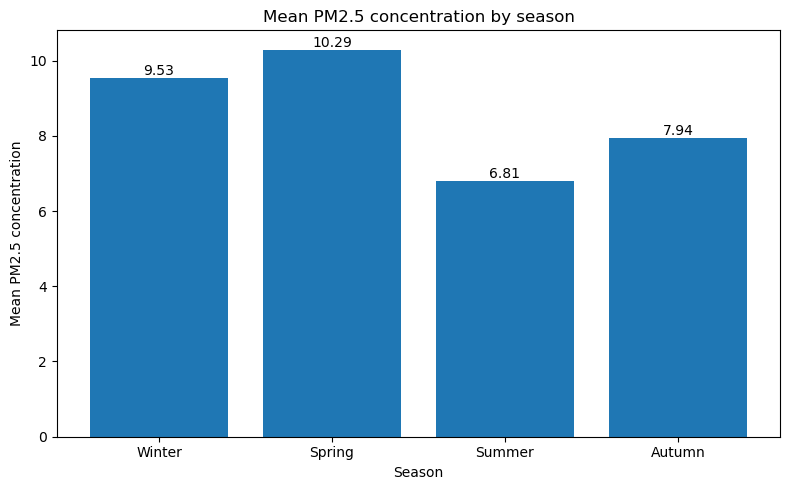

In [13]:
# ============================================================
# Step 4.3: Visualise seasonal PM2.5 patterns
# ============================================================

# Seasonal comparison helps show whether some parts of the year have generally
# higher PM2.5 concentrations. This matters because imputation difficulty may
# vary depending on seasonal pollution behaviour.

plt.figure(figsize=(8, 5))

bars = plt.bar(
    season_pm25_summary["Season"].astype(str),
    season_pm25_summary["Mean_PM25"]
)

plt.xlabel("Season")
plt.ylabel("Mean PM2.5 concentration")
plt.title("Mean PM2.5 concentration by season")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# Step 4.4: Hourly PM2.5 patterns
# ============================================================

# Hour-of-day patterns are examined because hourly PM2.5 data may contain
# daily cycles linked to traffic, heating, atmospheric conditions or reporting patterns.
# If hourly structure exists, later models should include hour-of-day and lag features.

hour_pm25_summary = (
    eda.groupby("Hour")
    .agg(
        Observed_PM25=("PM25", lambda x: x.notna().sum()),
        Mean_PM25=("PM25", "mean"),
        Median_PM25=("PM25", "median"),
        P95_PM25=("PM25", lambda x: x.quantile(0.95))
    )
    .reset_index()
)

hour_pm25_summary[["Mean_PM25", "Median_PM25", "P95_PM25"]] = (
    hour_pm25_summary[["Mean_PM25", "Median_PM25", "P95_PM25"]].round(2)
)

display(hour_pm25_summary)

,Hour,Observed_PM25,Mean_PM25,Median_PM25,P95_PM25
0,0,8939,9.50,7.00,25.57
1,1,8931,9.48,7.00,25.00
2,2,8936,9.11,6.78,24.59
3,3,8930,8.95,6.57,24.00
4,4,8925,8.90,6.51,24.00
5,5,8929,8.89,6.51,23.98
6,6,8934,8.98,6.60,24.53
7,7,8926,9.11,6.79,25.00
8,8,8926,9.16,6.79,25.40
9,9,8904,9.04,6.60,24.83


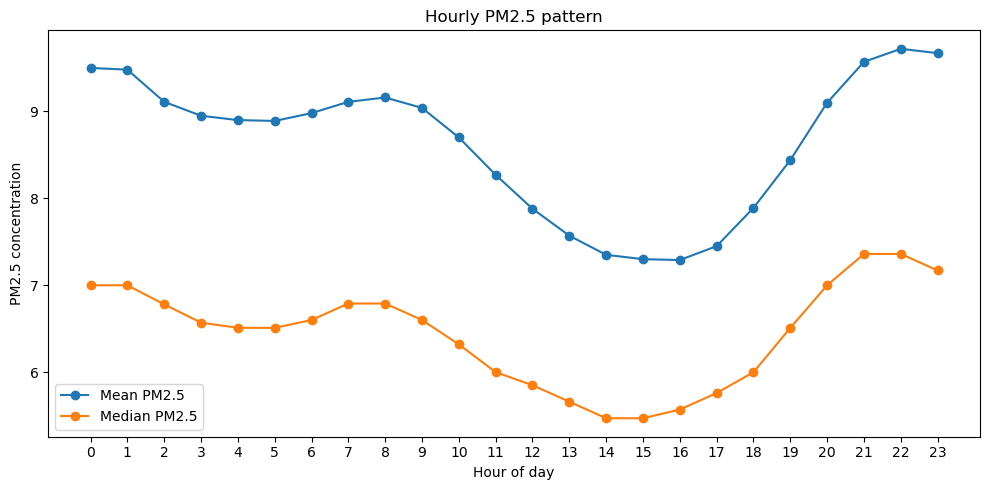

In [15]:
# ============================================================
# Step 4.5: Visualise hourly PM2.5 patterns
# ============================================================

# The hourly profile shows whether PM2.5 follows a daily cycle.
# A visible daily pattern supports the use of hour-of-day features and a 24-hour
# temporal context window in later imputation models.

plt.figure(figsize=(10, 5))

plt.plot(
    hour_pm25_summary["Hour"],
    hour_pm25_summary["Mean_PM25"],
    marker="o",
    label="Mean PM2.5"
)

plt.plot(
    hour_pm25_summary["Hour"],
    hour_pm25_summary["Median_PM25"],
    marker="o",
    label="Median PM2.5"
)

plt.xlabel("Hour of day")
plt.ylabel("PM2.5 concentration")
plt.title("Hourly PM2.5 pattern")
plt.xticks(range(0, 24))
plt.legend()

plt.tight_layout()
plt.show()

In [16]:
# ============================================================
# Step 4.6: Day-of-week PM2.5 patterns
# ============================================================

# Day-of-week patterns are examined because urban activity can differ between
# weekdays and weekends. If PM2.5 varies by day type, day-of-week may be useful
# as a calendar feature in machine-learning models.

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

day_pm25_summary = (
    eda.groupby("DayOfWeek")
    .agg(
        Observed_PM25=("PM25", lambda x: x.notna().sum()),
        Mean_PM25=("PM25", "mean"),
        Median_PM25=("PM25", "median"),
        P95_PM25=("PM25", lambda x: x.quantile(0.95))
    )
    .reset_index()
)

day_pm25_summary["DayOfWeek"] = pd.Categorical(
    day_pm25_summary["DayOfWeek"],
    categories=day_order,
    ordered=True
)

day_pm25_summary = day_pm25_summary.sort_values("DayOfWeek")

day_pm25_summary[["Mean_PM25", "Median_PM25", "P95_PM25"]] = (
    day_pm25_summary[["Mean_PM25", "Median_PM25", "P95_PM25"]].round(2)
)

display(day_pm25_summary)

,DayOfWeek,Observed_PM25,Mean_PM25,Median_PM25,P95_PM25
1,Monday,30628,8.70,6.13,23.68
5,Tuesday,30508,8.50,6.04,23.40
6,Wednesday,30264,8.98,6.42,25.38
4,Thursday,30349,8.29,6.42,21.16
0,Friday,30686,8.49,6.70,20.94
2,Saturday,30803,8.70,6.70,22.55
3,Sunday,30775,8.83,6.51,23.10


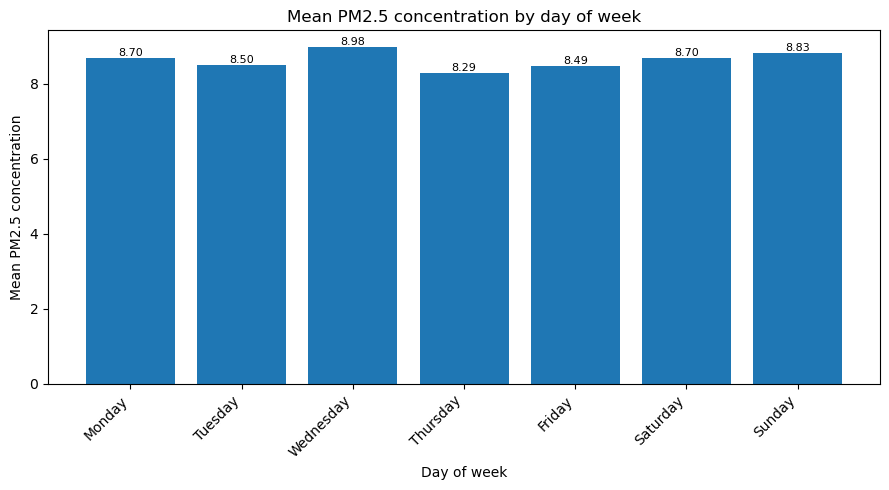

In [17]:
# ============================================================
# Step 4.7: Visualise day-of-week PM2.5 patterns
# ============================================================

# This figure checks whether PM2.5 differs across weekdays and weekends.
# If the differences are small, day-of-week may still be kept as a lightweight
# temporal feature, but it may be less important than hour or lag features.

plt.figure(figsize=(9, 5))

bars = plt.bar(
    day_pm25_summary["DayOfWeek"].astype(str),
    day_pm25_summary["Mean_PM25"]
)

plt.xlabel("Day of week")
plt.ylabel("Mean PM2.5 concentration")
plt.title("Mean PM2.5 concentration by day of week")

plt.xticks(rotation=45, ha="right")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()

### Step 4 interpretation

PM2.5 shows clear temporal variation. Monthly results show the highest mean concentration in March and the lowest values in July and August. Seasonally, spring and winter have higher PM2.5 levels than summeing.r.

The hourly profile also shows a daily pattern, with lower PM2.5 during the middle of the day and higher values in the evening and night. This supports the later use of time-based features such as month, season, hour-of-day and lagged PM2.5 values.

Day-of-week differences are smaller, so this feature may be less important than hour or seasonal variables. Overall, these findings show that simple global methods may miss temporal structure, while ML and DL models may benefit from temporal feature en

Across the five-year study period (2021–2025), annual mean PM2.5 concentrations 
do not show a strong monotonic secular trend. Year-on-year variation exists but 
no sustained upward or downward trajectory is apparent in the data, which 
suggests that long-term trend removal (such as first differencing purely for 
de-trending) is not required before modelling.gineering.

## Step 5: PM2.5 autocorrelation analysis

This step examines whether PM2.5 values are related to their previous hourly values. This is important because imputation models often use recent observations to estimate missing values.

If PM2.5 remains correlated across short time lags, then lagged PM2.5 features such as t-1 to t-24 are justified. This also supports the use of temporal models such as interpolation, Kalman/ARIMA and Bi-LSTM.

In [18]:
# ============================================================
# Step 5: PM2.5 autocorrelation by hourly lag
# ============================================================

# Autocorrelation is used to check whether PM2.5 values are related to their previous values.
# This matters because strong short-term dependence supports using lagged PM2.5 features
# in later statistical, machine-learning and deep-learning imputation models.

# Use the wide PM2.5 panel because autocorrelation is calculated separately for each station.
pm25_wide_indexed = pm25_wide.set_index("Datetime")

station_columns = [col for col in pm25_wide_indexed.columns]

max_lag = 48

autocorr_results = []

for station in station_columns:
    series = pm25_wide_indexed[station]

    for lag in range(1, max_lag + 1):
        autocorr_results.append({
            "Station": station,
            "Lag_hours": lag,
            "Autocorrelation": series.autocorr(lag=lag)
        })

autocorr_df = pd.DataFrame(autocorr_results)

display(autocorr_df.head())

,Station,Lag_hours,Autocorrelation
0,London Bexley,1,0.952668
1,London Bexley,2,0.897905
2,London Bexley,3,0.847214
3,London Bexley,4,0.800257
4,London Bexley,5,0.758294


In [19]:
# ============================================================
# Step 5.1: Average autocorrelation across stations
# ============================================================

# Averaging autocorrelation across stations gives a general view of temporal dependence
# in the final monitoring network.
# This helps decide whether a 24-hour lag window is reasonable for later modelling.

mean_autocorr = (
    autocorr_df.groupby("Lag_hours")
    .agg(
        Mean_autocorrelation=("Autocorrelation", "mean"),
        Min_autocorrelation=("Autocorrelation", "min"),
        Max_autocorrelation=("Autocorrelation", "max")
    )
    .reset_index()
)

mean_autocorr[["Mean_autocorrelation", "Min_autocorrelation", "Max_autocorrelation"]] = (
    mean_autocorr[["Mean_autocorrelation", "Min_autocorrelation", "Max_autocorrelation"]].round(3)
)

display(mean_autocorr.head(24))

,Lag_hours,Mean_autocorrelation,Min_autocorrelation,Max_autocorrelation
0,1,0.944,0.870,0.970
1,2,0.892,0.813,0.923
2,3,0.841,0.764,0.873
3,4,0.793,0.717,0.825
4,5,0.748,0.672,0.779
5,6,0.708,0.631,0.736
6,7,0.673,0.596,0.700
7,8,0.642,0.566,0.670
8,9,0.616,0.540,0.643
9,10,0.593,0.518,0.621


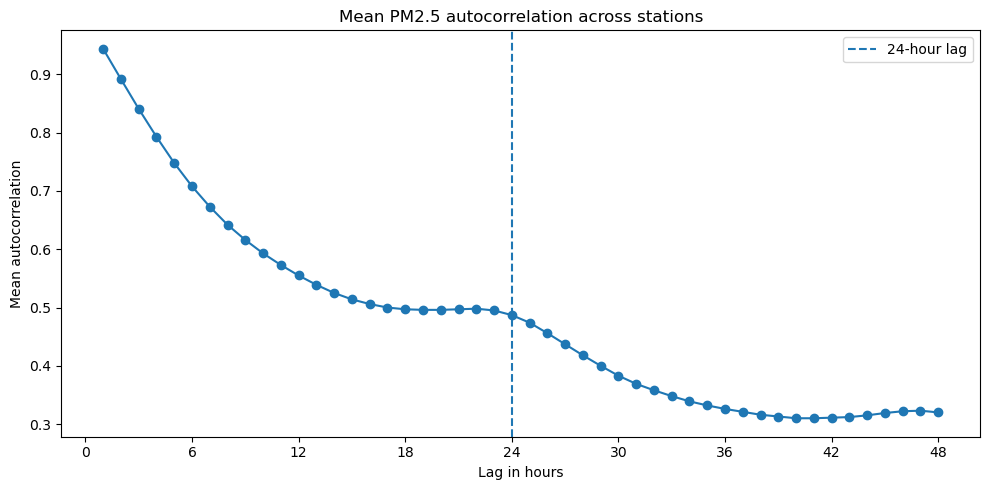

In [20]:
# ============================================================
# Step 5.2: Visualise average PM2.5 autocorrelation
# ============================================================

# This figure shows how quickly PM2.5 temporal dependence decreases as the lag increases.
# If correlation remains meaningful up to 24 hours, this supports using a one-day lag window.

plt.figure(figsize=(10, 5))

plt.plot(
    mean_autocorr["Lag_hours"],
    mean_autocorr["Mean_autocorrelation"],
    marker="o"
)

# A vertical line at 24 hours highlights the planned one-day temporal context window.
plt.axvline(24, linestyle="--", label="24-hour lag")

plt.xlabel("Lag in hours")
plt.ylabel("Mean autocorrelation")
plt.title("Mean PM2.5 autocorrelation across stations")

plt.xticks(range(0, max_lag + 1, 6))
plt.legend()

plt.tight_layout()
plt.show()

In [21]:
# ============================================================
# Step 5.3: Key autocorrelation lags by station
# ============================================================

# Selected lags are summarised because they connect directly to later feature engineering.
# Lag 1 represents very short-term dependence, while lag 24 represents the same hour
# on the previous day.

key_lags = [1, 2, 6, 12, 24, 48]

key_autocorr = (
    autocorr_df[autocorr_df["Lag_hours"].isin(key_lags)]
    .pivot(index="Station", columns="Lag_hours", values="Autocorrelation")
    .reset_index()
)

key_autocorr.columns = ["Station"] + [f"Lag_{lag}h" for lag in key_lags]

for col in key_autocorr.columns[1:]:
    key_autocorr[col] = key_autocorr[col].round(3)

display(key_autocorr)

,Station,Lag_1h,Lag_2h,Lag_6h,Lag_12h,Lag_24h,Lag_48h
0,London Bexley,0.953,0.898,0.722,0.584,0.500,0.329
1,London Harlington,0.962,0.909,0.732,0.583,0.504,0.343
2,London Honor Oak Park,0.967,0.915,0.718,0.561,0.497,0.327
3,London Marylebone Road,0.870,0.813,0.631,0.483,0.442,0.281
4,London N. Kensington,0.970,0.923,0.736,0.563,0.493,0.321


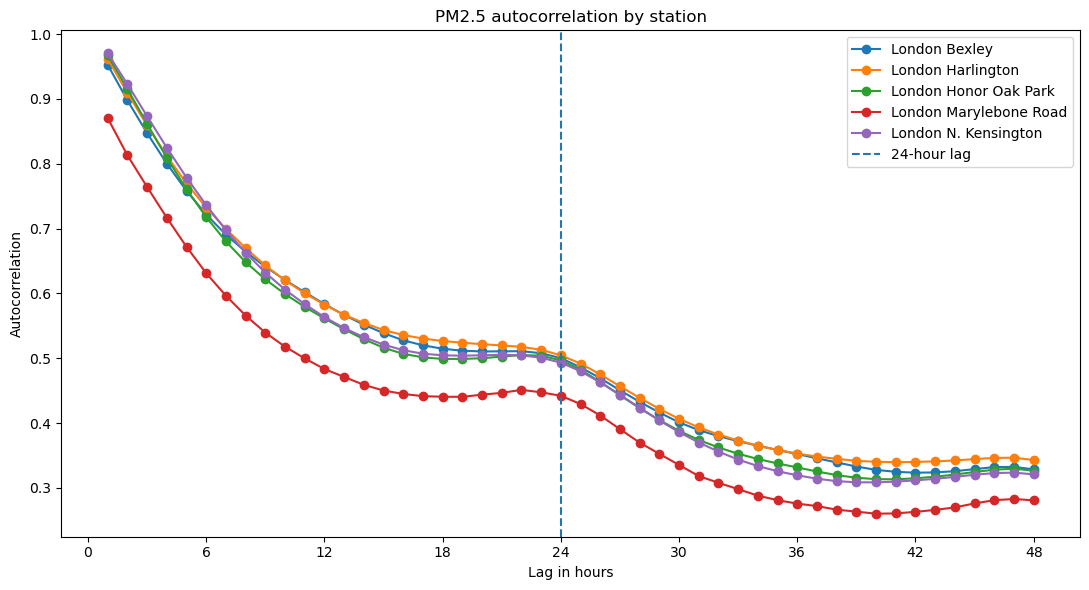

In [22]:
# ============================================================
# Step 5.4: Visualise autocorrelation by station
# ============================================================

# Station-specific autocorrelation curves show whether temporal dependence is similar
# across monitoring sites or whether some stations behave differently.
# This is useful because station-specific temporal behaviour may affect imputation difficulty.

plt.figure(figsize=(11, 6))

for station in station_columns:
    station_data = autocorr_df[autocorr_df["Station"] == station]

    plt.plot(
        station_data["Lag_hours"],
        station_data["Autocorrelation"],
        marker="o",
        label=station
    )

plt.axvline(24, linestyle="--", label="24-hour lag")

plt.xlabel("Lag in hours")
plt.ylabel("Autocorrelation")
plt.title("PM2.5 autocorrelation by station")

plt.xticks(range(0, max_lag + 1, 6))
plt.legend()
plt.tight_layout()
plt.show()

### Step 5 interpretation

The autocorrelation analysis shows strong temporal dependence in PM2.5. The average autocorrelation is very high at short lags, with a mean value of 0.944 at lag 1 hour. Although autocorrelation gradually decreases as the lag increases, it remains meaningful at lag 24 hours, at around 0.49.

This supports the use of lagged PM2.5 features in later imputation models. In particular, the 24-hour lag window is justified because PM2.5 still contains useful information from the same hour on the previous day.

Station-specific results show a similar decreasing pattern across all stations, although London Marylebone Road has slightly lower autocorrelation than the other stations. This suggests that temporal dependence exists across the monitoring network, but some stations may be harder to model than others.

Overall, this analysis supports the use of temporal methods such as interpolation, Kalman/ARIMA, lag-based machine-learning models and a 24-hour Bi-LSTM input window.


## Step 6: Stationarity and PACF analysis for ARIMA diagnostics

This step checks whether the PM2.5 time series is stationary and examines partial autocorrelation patterns. This is important because ARIMA-based models require decisions about differencing and autoregressive lag order.

The diagnostics are calculated using the training period only (2021-2023) to avoid using validation or test information when motivating later model choices. Because ADF and PACF require complete series, missing PM2.5 values are time-interpolated only for this diagnostic analysis. This interpolation is not used to create the final modelling target.

In [23]:
# ============================================================
# Step 6: Prepare training-only PM2.5 series for ARIMA diagnostics
# ============================================================

# ARIMA diagnostics are based only on the training years.
# This avoids using validation or test information when deciding modelling assumptions.

from statsmodels.tsa.stattools import adfuller, pacf
from statsmodels.graphics.tsaplots import plot_pacf

arima_train = eda[eda["RawYear"].isin([2021, 2022, 2023])].copy()

# Convert the long station-hour table into a wide time-series format.
# Each station becomes one column, which allows station-specific ADF and PACF checks.
arima_wide = (
    arima_train
    .pivot(index="Datetime", columns="Station", values="PM25")
    .sort_index()
)

# Force an hourly frequency so that the diagnostic series keeps the correct time structure.
arima_wide = arima_wide.asfreq("h")

print("ARIMA diagnostic training period shape:", arima_wide.shape)
display(arima_wide.head())

ARIMA diagnostic training period shape: (26280, 5)


Station,London Bexley,London Harlington,London Honor Oak Park,London Marylebone Road,London N. Kensington
Datetime,,,,,
2021-01-01 01:00:00,39.552,22.453,29.316,18.6,30.448
2021-01-01 02:00:00,52.359,19.099,19.293,40.3,55.802
2021-01-01 03:00:00,20.920,20.925,16.604,23.9,28.278
2021-01-01 04:00:00,15.943,19.974,15.330,18.1,15.613
2021-01-01 05:00:00,17.076,17.363,17.807,21.7,19.764


In [25]:
# ============================================================
# Step 6.1: Augmented Dickey-Fuller stationarity test
# ============================================================

# The ADF test checks whether a time series has a unit root.
# If p-value < 0.05, we reject the unit-root hypothesis and treat the series
# as stationary for this diagnostic purpose.
#
# Three versions are checked:
# 1. Original PM2.5 series
# 2. First-differenced series
# 3. 24-hour seasonal-differenced series
#
# This helps discuss whether ARIMA differencing may be needed.

def prepare_diagnostic_series(series):
    # ADF requires no missing values.
    # Time interpolation is used only for diagnostic continuity, not for final modelling.
    return series.astype(float).interpolate(method="time", limit_direction="both")


def run_adf_test(series, station, transformation):
    result = adfuller(
        series.dropna(),
        maxlag=48,
        autolag="AIC"
    )

    return {
        "Station": station,
        "Transformation": transformation,
        "ADF_statistic": result[0],
        "p_value": result[1],
        "Used_lags": result[2],
        "Observations": result[3],
        "Stationary_at_5pct": result[1] < 0.05
    }


adf_records = []

for station in arima_wide.columns:
    original_series = prepare_diagnostic_series(arima_wide[station])

    transformations = {
        "Original": original_series,
        "First_difference": original_series.diff().dropna(),
        "Seasonal_difference_24h": original_series.diff(24).dropna()
    }

    for transformation_name, transformed_series in transformations.items():
        adf_records.append(
            run_adf_test(
                transformed_series,
                station,
                transformation_name
            )
        )

adf_results = pd.DataFrame(adf_records)

adf_results[["ADF_statistic", "p_value"]] = (
    adf_results[["ADF_statistic", "p_value"]].round(4)
)

display(adf_results)

,Station,Transformation,ADF_statistic,p_value,Used_lags,Observations,Stationary_at_5pct
0,London Bexley,Original,-13.2844,0.0,48,26231,True
1,London Bexley,First_difference,-30.0619,0.0,48,26230,True
2,London Bexley,Seasonal_difference_24h,-24.9503,0.0,48,26207,True
3,London Harlington,Original,-13.5880,0.0,48,26231,True
4,London Harlington,First_difference,-29.9620,0.0,48,26230,True
5,London Harlington,Seasonal_difference_24h,-23.9823,0.0,48,26207,True
6,London Honor Oak Park,Original,-13.5319,0.0,48,26231,True
7,London Honor Oak Park,First_difference,-30.0206,0.0,48,26230,True
8,London Honor Oak Park,Seasonal_difference_24h,-23.8602,0.0,48,26207,True
9,London Marylebone Road,Original,-12.9527,0.0,48,26231,True


In [26]:
# ============================================================
# Step 6.2: PACF values at key lags
# ============================================================

# PACF helps identify direct autoregressive dependence after controlling for shorter lags.
# Key lags are checked because hourly PM2.5 may depend on recent hours and daily cycles.
# This supports later discussion of AR terms in ARIMA/Kalman-ARIMA models.

key_lags = [1, 2, 3, 6, 12, 24, 48]
pacf_records = []

for station in arima_wide.columns:
    series = prepare_diagnostic_series(arima_wide[station])

    pacf_values = pacf(
        series.dropna(),
        nlags=max(key_lags),
        method="ywm"
    )

    record = {"Station": station}

    for lag in key_lags:
        record[f"PACF_lag_{lag}h"] = pacf_values[lag]

    pacf_records.append(record)

pacf_key_lags = pd.DataFrame(pacf_records)

for col in pacf_key_lags.columns:
    if col != "Station":
        pacf_key_lags[col] = pacf_key_lags[col].round(3)

display(pacf_key_lags)

,Station,PACF_lag_1h,PACF_lag_2h,PACF_lag_3h,PACF_lag_6h,PACF_lag_12h,PACF_lag_24h,PACF_lag_48h
0,London Bexley,0.948,-0.123,0.023,0.039,-0.001,-0.014,-0.028
1,London Harlington,0.960,-0.181,-0.011,0.019,0.011,-0.041,-0.026
2,London Honor Oak Park,0.964,-0.314,0.021,0.032,0.004,-0.054,-0.029
3,London Marylebone Road,0.906,0.172,0.035,0.012,0.026,-0.010,-0.014
4,London N. Kensington,0.968,-0.330,0.040,0.009,0.013,-0.034,-0.029


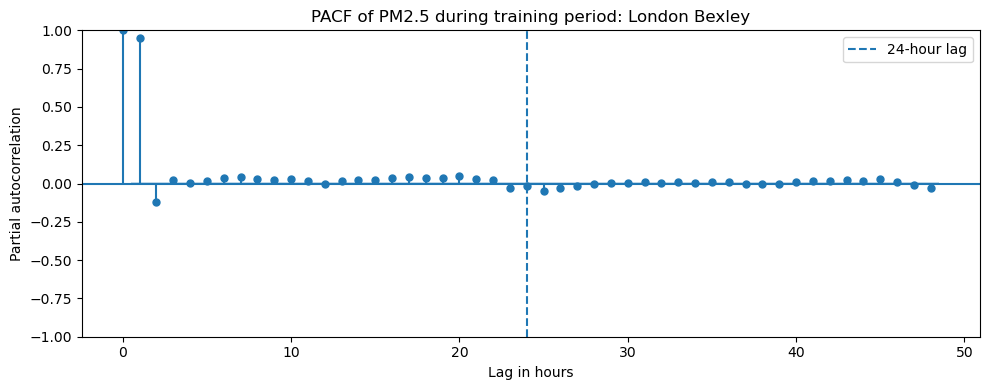

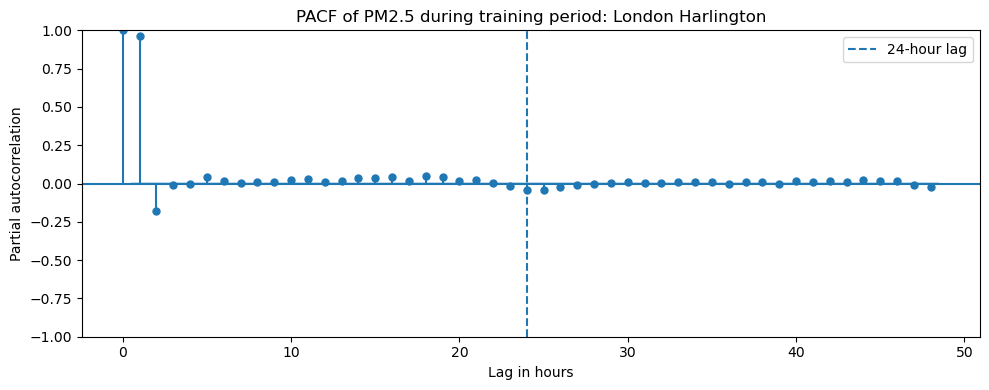

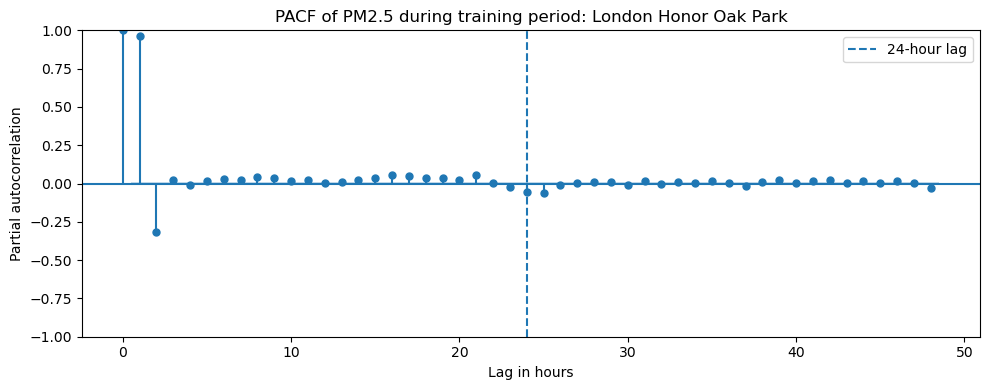

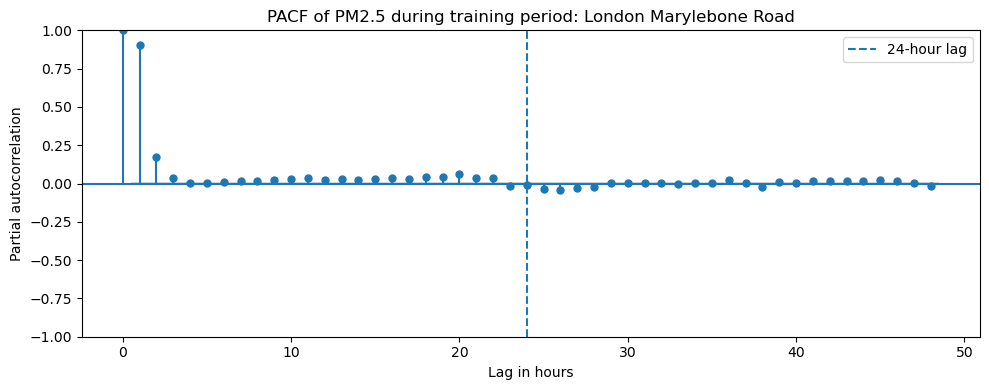

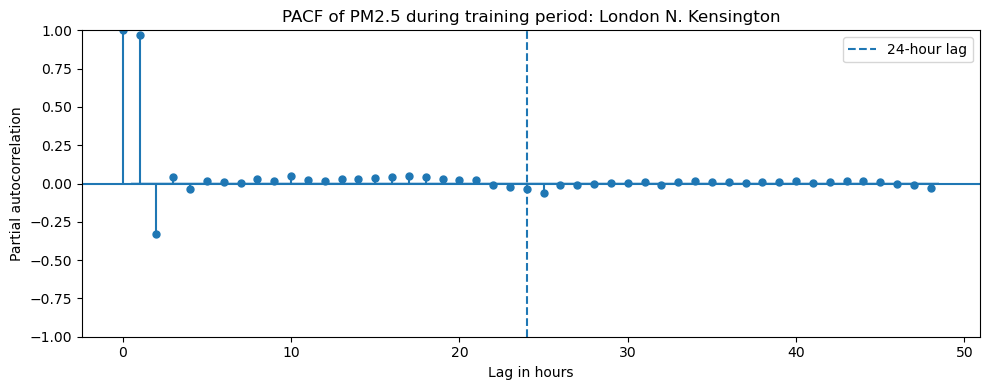

In [27]:
# ============================================================
# Step 6.3: Visualise PACF by station
# ============================================================

# PACF plots show which lags remain important after accounting for earlier lags.
# The 24-hour line is included because hourly air pollution data often have daily structure.

for station in arima_wide.columns:
    series = prepare_diagnostic_series(arima_wide[station])

    fig, ax = plt.subplots(figsize=(10, 4))

    plot_pacf(
        series.dropna(),
        lags=48,
        method="ywm",
        alpha=0.05,
        ax=ax
    )

    ax.axvline(
        x=24,
        linestyle="--",
        label="24-hour lag"
    )

    ax.set_title(f"PACF of PM2.5 during training period: {station}")
    ax.set_xlabel("Lag in hours")
    ax.set_ylabel("Partial autocorrelation")
    ax.legend()

    plt.tight_layout()
    plt.show()

### Step 6 interpretation

The ADF results suggest that the original PM2.5 training series is stationary across all five monitoring stations. The p-values are effectively below 0.05 for the original series as well as for the first-differenced and 24-hour seasonal-differenced versions. This indicates that strong additional differencing is not clearly required for the ARIMA diagnostic stage.

The PACF results show that the strongest direct temporal dependence is concentrated at the 1-hour lag. The PACF at lag 1 is very high across all stations, ranging from approximately 0.906 at London Marylebone Road to 0.968 at London N. Kensington. After the first few lags, the partial autocorrelations become small, including at the 24-hour and 48-hour lags.

This means that although the earlier autocorrelation analysis showed meaningful 24-hour dependence, the PACF suggests that much of this daily structure is explained indirectly through shorter recent lags. Therefore, for the Kalman-ARIMA model, the EDA supports starting with low-order autoregressive structures, such as ARIMA models with small p values, while avoiding unnecessary high-order seasonal AR terms unless later validation results justify them.

Overall, this analysis strengthens the methodological justification for including temporal models in the dissertation. It also supports the use of recent lagged PM2.5 values in machine-learning models and the 24-hour input window for the Bi-LSTM, while showing that ARIMA order selection should be guided mainly by short-lag dependence rather than a strong direct 24-hour PACF effect.